
# ShipCall AI — Autonomous Experiment Readout & Ship/Hold/Iterate/Kill Decision Agent

**What this is:** an agent that reviews a completed A/B test and outputs
one of four decisions — **SHIP, HOLD, ITERATE, or KILL** — by running a
fixed diagnostic playbook (a Sample Ratio Mismatch check, guardrail-metric
checks, and a formal heterogeneous-treatment-effect test) before an LLM
ever synthesizes a recommendation, then applying an explicit decision
rubric so the model's job is to *apply the rule correctly*, not invent one.

**Why this matters more than "read the primary metric's p-value":** the 5
experiments below were deliberately built so that a primary-metric-only
read gets **3 of the 5 wrong** — one looks like a clean win but hides a
guardrail violation, one looks like a null result but hides a real
segment-specific win, and one looks significant but is actually
untrustworthy due to a broken randomization pipeline. An agent that always
says "ship it" when the primary metric is positive isn't doing
experimentation review, it's cheerleading — this project is built to
demonstrate the opposite.

**On the LLM backend:** same cached/live design as the rest of this
portfolio — see `../shared/llm_client.py`. Every decision memo below was
authored by reading the *actual* diagnostic output computed in this
notebook, not invented.


In [1]:

import sys, json
sys.path.insert(0, "../../shared")
sys.path.insert(0, "../pipeline")
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from srm import check_srm
from guardrails import check_all_guardrails
from hte import test_heterogeneous_effects
from ab_testing_lite import two_proportion_summary
from agent import review_experiment
from llm_client import get_client

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

experiments = json.load(open("../data/experiments.json"))["experiments"]
print(f"{len(experiments)} experiments loaded for review")


5 experiments loaded for review


## The Decision Rubric

Applied in strict order, every time:

1. **SRM detected** -> `INVALID` (don't interpret anything else)
2. **Else, guardrail violated** -> `HOLD`
3. **Else, significant segment-level heterogeneity** -> `ITERATE`
4. **Else, primary metric significant + positive** -> `SHIP`
5. **Else** -> `KILL`

## Reviewing All 5 Experiments

In [2]:

client = get_client(cache_file="../cached_responses.json")
memos = {}
for e in experiments:
    memo = review_experiment(e, client)
    memos[e["experiment_id"]] = memo
    print(f"{'='*90}\n{memo.name}\n{'-'*90}")
    print(memo.narrative)
    print()


Onboarding Redesign v2
------------------------------------------------------------------------------------------
RECOMMENDATION: SHIP

EVIDENCE: Primary metric (activation_rate) moved from 43.5% (control) to 47.5% (treatment), a +4.02pp lift, z=4.04, p=5.4e-05 -- clearly significant. The SRM check passed cleanly (observed split 50.0% vs. expected 50.0%, p=1.00). Both guardrails moved in the FAVORABLE direction and neither is a violation: day7_churn_rate -0.28pp (p=0.61), support_tickets_rate -0.48pp (p=0.46). The segment-level breakdown shows a positive lift in all three segments (Starter +3.12pp, Growth +6.23pp, Enterprise +1.87pp) with no statistically significant treatment:segment interaction (p=0.163, p=0.659) -- the effect is broadly consistent, not concentrated in one segment.

RATIONALE: This is rule (4) of the decision rubric -- no SRM, no guardrail violation, no significant heterogeneous effect, and a significant positive primary result. There is no reason in this evidence to

New Pricing Page Layout
------------------------------------------------------------------------------------------
RECOMMENDATION: ITERATE

EVIDENCE: The overall primary metric (trial_signup_rate) is essentially flat: 22.4% control vs. 22.5% treatment, z=0.09, p=0.930 -- not significant. But the segment breakdown tells a very different story: Starter -2.57pp (18.7% relative decline), Growth +1.90pp, Enterprise +4.30pp (a ~14% relative increase) -- and the treatment:segment interaction terms are both statistically significant (Growth vs. Starter reference: p=0.0058; Enterprise vs. Starter reference: p=0.0017), confirming the segment-level differences are real, not noise averaging to a false null. SRM check passed (p=1.00); both guardrails clean (p=0.454, p=0.638).

RATIONALE: This is rule (3) of the decision rubric. A flat overall average with a statistically confirmed, opposite-signed effect by segment is exactly the pattern a blanket ship/kill decision would get wrong in one direction

## The Diagnostic Evidence Behind Each Decision

In [3]:

summary_rows = []
for eid, memo in memos.items():
    decision = memo.narrative.split("\n")[0].replace("RECOMMENDATION: ", "")
    summary_rows.append({
        "experiment": memo.name, "decision": decision,
        "primary_lift_pp": round(memo.primary_result["lift_pp"], 2),
        "primary_p": round(memo.primary_result["p_value"], 4),
        "srm_detected": memo.srm.is_srm,
        "guardrail_violated": any(g.violated for g in memo.guardrail_results),
        "significant_hte": memo.hte.any_significant_interaction,
    })
summary_df = pd.DataFrame(summary_rows)
summary_df


,experiment,decision,primary_lift_pp,primary_p,srm_detected,guardrail_violated,significant_hte
0,Onboarding Redesign v2,SHIP,4.02,0.0001,False,False,False
1,Aggressive Upsell Banner,HOLD,2.12,0.0032,False,True,False
2,New Pricing Page Layout,ITERATE,0.07,0.9303,False,False,True
3,Search Ranking Algorithm v3,INVALID,3.83,0.0000,True,False,False
4,Dashboard Load Speed Optimization,KILL,-0.28,0.8043,False,False,False


**This table is the whole point of the project in one view:** 3 of
the 5 decisions (HOLD, ITERATE, INVALID) would be gotten wrong by a
process that only looks at the primary metric's significance and
direction — the diagnostic playbook is what turns "the number went up" into
a decision that's actually safe to act on.

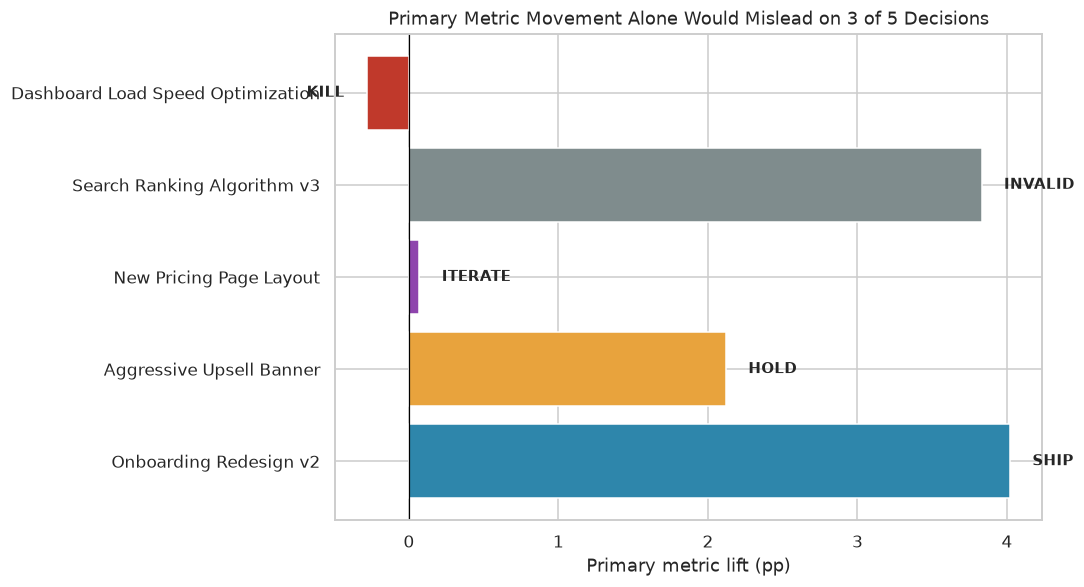

In [4]:

colors = {"SHIP": "#2E86AB", "HOLD": "#E8A33D", "ITERATE": "#8E44AD", "INVALID": "#7F8C8D", "KILL": "#C0392B"}
fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(summary_df.experiment, summary_df.primary_lift_pp,
                color=[colors[d] for d in summary_df.decision])
for bar, decision in zip(bars, summary_df.decision):
    ax.text(bar.get_width() + (0.15 if bar.get_width() >= 0 else -0.15), bar.get_y() + bar.get_height()/2,
            decision, va="center", ha="left" if bar.get_width() >= 0 else "right", fontweight="bold", fontsize=10)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Primary metric lift (pp)")
ax.set_title("Primary Metric Movement Alone Would Mislead on 3 of 5 Decisions")
plt.tight_layout()
plt.savefig("../dashboard/decisions_overview.png", dpi=150)
plt.show()


## Deep Dive — New Pricing Page Layout (the ITERATE case)

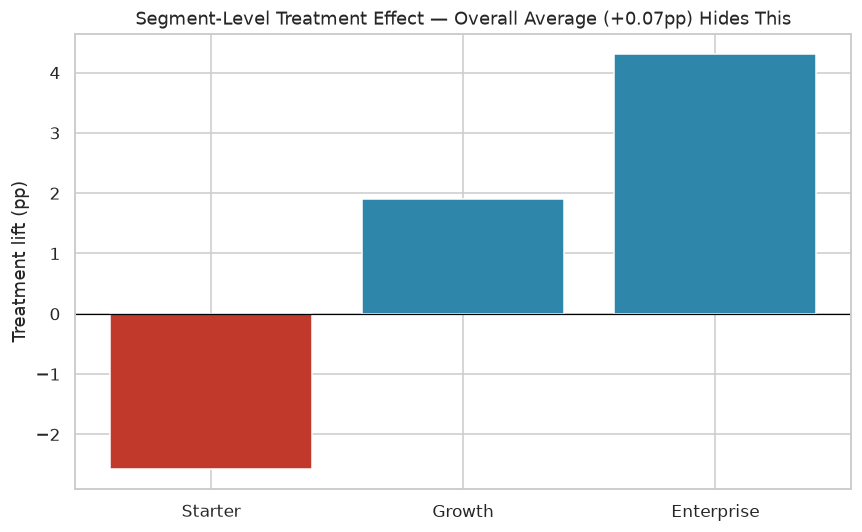

Interaction p-values (vs. Starter reference): {'treatment:C(segment)[T.Growth]': 0.005797142540321346, 'treatment:C(segment)[T.Enterprise]': 0.0016716622543293965}


In [5]:

hte = memos["new_pricing_page_layout"].hte
fig, ax = plt.subplots(figsize=(8, 5))
seg_colors = ["#C0392B" if l < 0 else "#2E86AB" for l in hte.segment_effects.lift_pp]
ax.bar(hte.segment_effects.segment, hte.segment_effects.lift_pp, color=seg_colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Treatment lift (pp)")
ax.set_title("Segment-Level Treatment Effect — Overall Average (+0.07pp) Hides This")
plt.tight_layout()
plt.savefig("../dashboard/hte_pricing.png", dpi=150)
plt.show()
print(f"Interaction p-values (vs. Starter reference): {hte.interaction_p_values}")


## Deep Dive — Search Ranking Algorithm v3 (the INVALID/SRM case)

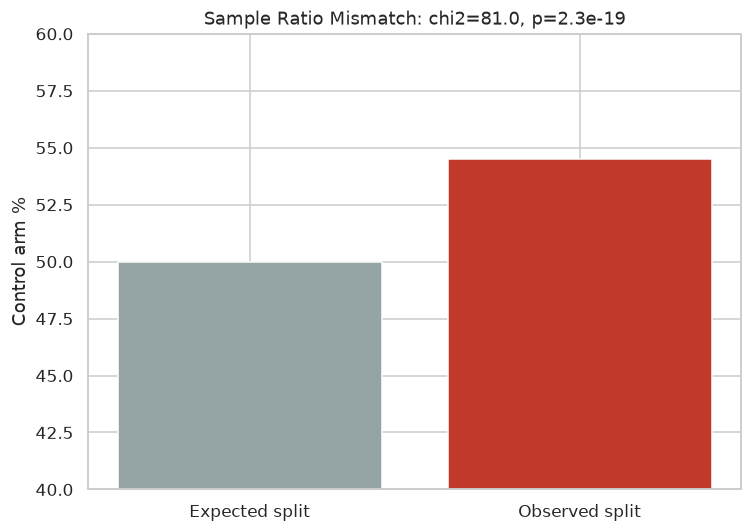

A primary-metric-only reviewer would have shipped this. The SRM check is what stops that.


In [6]:

srm = memos["search_ranking_algo_v3"].srm
fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(["Expected split", "Observed split"], [srm.expected_ratio*100, srm.observed_ratio*100],
       color=["#95A5A6", "#C0392B"])
ax.set_ylabel("Control arm %")
ax.set_ylim(40, 60)
ax.set_title(f"Sample Ratio Mismatch: chi2={srm.chi2:.1f}, p={srm.p_value:.1e}")
plt.tight_layout()
plt.savefig("../dashboard/srm_search.png", dpi=150)
plt.show()
print("A primary-metric-only reviewer would have shipped this. The SRM check is what stops that.")


## Executive Summary & Recommendations


1. **The primary metric alone is not a decision process** — of the 5
   experiments reviewed, only 2 (Onboarding Redesign v2: SHIP; Dashboard
   Load Speed: KILL) would get the same answer from "just look at whether
   the number went up significantly." The other 3 needed a guardrail
   check, an HTE test, or an SRM check to reach the right call.
2. **Aggressive Upsell Banner is the highest-value catch**: a
   statistically significant, positive primary-metric result that a
   naive process would ship — but it comes with a larger relative
   increase in 7-day churn, a real net-negative-for-retention risk.
3. **New Pricing Page Layout is the most commercially interesting
   finding**: an apparently-null overall result is actually a validated
   win for Enterprise (+4.30pp) and a validated loss for Starter
   (-2.57pp) — averaging them together would have thrown away a real,
   segment-specific opportunity.
4. **Search Ranking Algorithm v3 is the most dangerous case if missed**:
   a seemingly clean, significant, positive result that is actually
   uninterpretable due to a broken randomization pipeline (SRM
   chi2=81.0, p=2.3e-19) — shipping this would have been shipping a
   coin-flip dressed up as a finding.
5. **Recommendation:** make the SRM check → guardrail check → HTE check
   sequence a mandatory automated gate before any experiment result
   reaches a human reviewer or a dashboard, not an optional step an
   analyst remembers to run — 2 of the 3 "wrong at first glance"
   decisions here were only catchable because the checks ran
   automatically, in order, every time.
